# Lab 01 · 표본, 부트스트랩, p-value, 다중검정, Lasso

**이 실습이 다루는 자료** ([필독 목록](../READING_LIST.md) · [실습 가이드](../PRACTICE.md))

| 절 | 직접 확인할 것 | 관련 자료 |
|---|---|---|
| 1–2 | 표준편차 vs 표준오차, 중심극한정리, 신뢰구간의 "95%"가 뜻하는 것 | 3Blue1Brown CLT 영상, [확률·통계 기초](../../00_Foundations/03_probability-statistics.md) |
| 3 | 공식 없이 신뢰구간 만들기 | Efron (1979) *Bootstrap Methods* |
| 4–5 | 귀무가설이 참일 때 p-value는 어떻게 분포하는가, 유의성 ≠ 효과 크기 | ASA Statement on p-Values (2016) |
| 6 | 검정을 많이 하면 생기는 일과 FDR 보정 | Benjamini & Hochberg (1995) |
| 7 | L1 벌점이 계수를 정확히 0으로 만드는 모습 | Tibshirani (1996) *Lasso* |

**진행 방법**: 각 절의 `✍️ 예측` 질문에 먼저 답을 적고(머릿속으로라도) 셀을 실행하세요. 예측이 틀린 곳이 곧 배울 곳입니다.  
**소요 시간**: 60~90분 · **필요 패키지**: numpy, pandas, scipy, matplotlib, scikit-learn, statsmodels (Colab 기본 포함)

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (7, 3.5), "figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

## 1. 표준편차(SD)와 표준오차(SE), 그리고 중심극한정리

모집단으로 한쪽으로 치우친 **지수분포**(평균 1, 표준편차 1)를 쓰겠습니다. 정규분포가 아니라는 점이 중요합니다.

- **표준편차(SD)**: 개별 데이터가 퍼진 정도
- **표준오차(SE)**: 표본으로 계산한 *추정치(예: 평균)* 가 표본을 다시 뽑을 때마다 흔들리는 정도. 이론값은 $\sigma/\sqrt{n}$

✍️ **예측**: 표본 크기 n을 2 → 10 → 50으로 키우면 "표본 평균들의 히스토그램" 모양과 폭은 어떻게 변할까요?

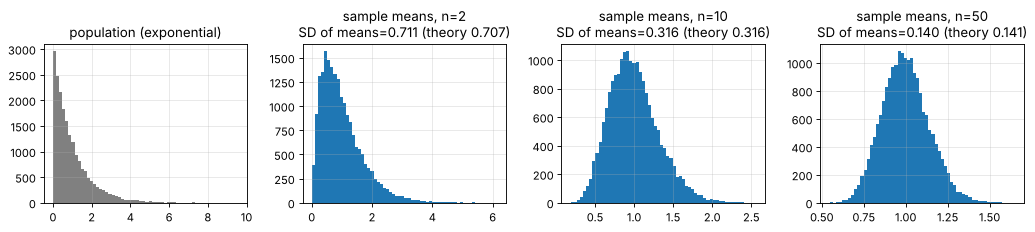

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
axes[0].hist(rng.exponential(1.0, 20000), bins=60, color="gray")
axes[0].set_title("population (exponential)")
for ax, n in zip(axes[1:], [2, 10, 50]):
    means = rng.exponential(1.0, size=(20000, n)).mean(axis=1)   # 표본을 20,000번 다시 뽑아 평균 계산
    ax.hist(means, bins=60, color="tab:blue")
    ax.set_title(f"sample means, n={n}\nSD of means={means.std():.3f} (theory {1/np.sqrt(n):.3f})")
plt.tight_layout(); plt.show()

**관찰할 것**
- 원래 분포는 심하게 치우쳐 있지만, 표본 평균의 분포는 n이 커질수록 종 모양(정규분포)에 가까워집니다 → **중심극한정리(CLT)**.
- 평균들의 흩어짐(= 표준오차)은 이론값 $1/\sqrt{n}$ 과 거의 일치합니다. n을 4배로 늘려야 SE가 절반이 됩니다.
- 논문의 `± 0.3` 이 SD인지 SE인지에 따라 의미가 전혀 다릅니다. 캡션을 확인하는 습관을 들이세요.

## 2. 신뢰구간의 "95%"는 무엇의 95%인가

95% 신뢰구간은 "참값이 이 구간에 있을 확률이 95%"가 아니라, **같은 절차를 반복하면 그렇게 만든 구간들의 약 95%가 참값을 포함한다**는 뜻입니다. 직접 세어 봅시다.

✍️ **예측**: n=10일 때와 n=100일 때, 포함 비율(coverage)은 둘 다 정확히 95%일까요?

In [3]:
def coverage(n, reps=20000, true_mean=1.0):
    x = rng.exponential(true_mean, size=(reps, n))
    m, se = x.mean(axis=1), x.std(axis=1, ddof=1) / np.sqrt(n)
    tcrit = stats.t.ppf(0.975, df=n - 1)
    return np.mean((m - tcrit * se <= true_mean) & (true_mean <= m + tcrit * se))

for n in [5, 10, 30, 100, 500]:
    print(f"n={n:4d}  95% CI가 참값을 포함한 비율 = {coverage(n):.3f}")

n=   5  95% CI가 참값을 포함한 비율 = 0.881
n=  10  95% CI가 참값을 포함한 비율 = 0.900
n=  30  95% CI가 참값을 포함한 비율 = 0.924
n= 100  95% CI가 참값을 포함한 비율 = 0.942
n= 500  95% CI가 참값을 포함한 비율 = 0.948


표본이 작고 분포가 치우쳐 있으면 "95%" 구간이 실제로는 95%보다 덜 포함합니다. t-구간은 **근사**이고, 근사가 얼마나 좋은지는 n과 분포 모양에 달려 있습니다.

## 3. 부트스트랩: 공식이 없을 때 신뢰구간 만들기 (Efron, 1979)

평균의 SE는 공식이 있지만 **중앙값**, 상관계수, 모델의 AUC 같은 통계량은 간단한 공식이 없습니다.  
부트스트랩의 발상: *가진 표본을 모집단처럼 취급해서, 거기서 복원추출로 표본을 다시 뽑는다.*

표본 중앙값 = 22.09
부트스트랩 95% CI (percentile) = [16.82, 28.48]   (모집단의 참 중앙값 = 20.09)


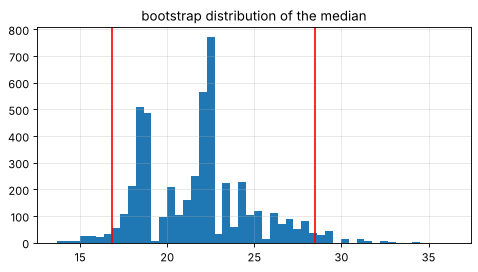

In [4]:
sample = rng.lognormal(mean=3.0, sigma=0.8, size=80)        # 예: 80명의 주문 금액 (치우친 분포)
B = 5000
idx = rng.integers(0, len(sample), size=(B, len(sample)))    # 복원추출 인덱스
boot_medians = np.median(sample[idx], axis=1)
lo, hi = np.percentile(boot_medians, [2.5, 97.5])
print(f"표본 중앙값 = {np.median(sample):.2f}")
print(f"부트스트랩 95% CI (percentile) = [{lo:.2f}, {hi:.2f}]   (모집단의 참 중앙값 = {np.exp(3.0):.2f})")
plt.hist(boot_medians, bins=50); plt.axvline(lo, c="r"); plt.axvline(hi, c="r")
plt.title("bootstrap distribution of the median"); plt.show()

부트스트랩 구간도 절차이므로 **coverage를 검증**할 수 있습니다. 아래는 "표본 뽑기 → 부트스트랩 구간 만들기"를 1,000번 반복해 참 중앙값을 포함한 비율을 셉니다.

In [5]:
def boot_ci_median(x, B=1000):
    idx = rng.integers(0, len(x), size=(B, len(x)))
    return np.percentile(np.median(x[idx], axis=1), [2.5, 97.5])

hits = 0
for _ in range(1000):
    x = rng.lognormal(3.0, 0.8, size=80)
    lo, hi = boot_ci_median(x)
    hits += (lo <= np.exp(3.0) <= hi)
print("부트스트랩 구간의 coverage ≈", hits / 1000)

부트스트랩 구간의 coverage ≈ 0.958


## 4. 귀무가설이 참일 때 p-value의 분포 (ASA Statement, 2016)

두 그룹에 **아무 차이가 없는** A/A 실험을 10,000번 합니다.

✍️ **예측**: p-value 10,000개의 히스토그램은 어떤 모양일까요? 0.05보다 작은 것은 몇 %일까요?

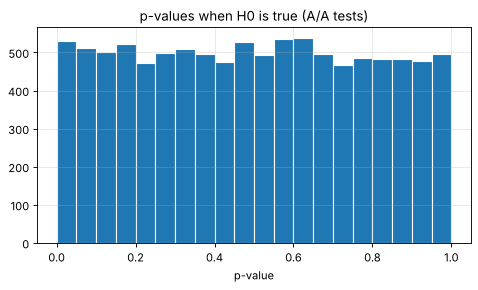

p < 0.05 비율 = 0.053


In [6]:
pvals = np.array([stats.ttest_ind(rng.normal(0, 1, 100), rng.normal(0, 1, 100)).pvalue for _ in range(10000)])
plt.hist(pvals, bins=20, edgecolor="white"); plt.title("p-values when H0 is true (A/A tests)"); plt.xlabel("p-value"); plt.show()
print(f"p < 0.05 비율 = {np.mean(pvals < 0.05):.3f}")

귀무가설이 참이면 p-value는 **균등분포**입니다. 그래서 유의수준 0.05는 "차이가 없는데도 있다고 할 확률(1종 오류)"을 5%로 정한 것입니다.  
p-value는 "귀무가설이 참일 확률"이 **아닙니다**. 귀무가설이 참이라는 가정 아래에서 계산한 값입니다.

## 5. 유의성 ≠ 효과 크기

✍️ **예측**: (가) 효과가 아주 작은데 표본이 100만 개, (나) 효과가 큰데 표본이 10개. 어느 쪽 p-value가 더 작을까요?

In [7]:
def experiment(effect, n):
    a, b = rng.normal(0, 1, n), rng.normal(effect, 1, n)
    diff = b.mean() - a.mean()
    se = np.sqrt(a.var(ddof=1) / n + b.var(ddof=1) / n)
    return dict(effect=effect, n=n, diff=round(diff, 4), ci_low=round(diff - 1.96 * se, 4), ci_high=round(diff + 1.96 * se, 4),
                p=stats.ttest_ind(a, b).pvalue)

pd.DataFrame([experiment(0.01, 1_000_000), experiment(0.8, 10)])

,effect,n,diff,ci_low,ci_high,p
0,0.01,1000000,0.0093,0.0065,0.0120,5.563324e-11
1,0.80,10,0.7736,-0.0951,1.6424,9.794703e-02


- (가)는 p가 매우 작지만 차이는 표준편차의 1% 수준입니다. 실무적으로 의미가 있는지는 별개의 판단입니다.
- (나)는 효과가 크지만 표본이 작아 신뢰구간이 매우 넓습니다(실행할 때마다 유의 여부가 바뀝니다).
- 그래서 ASA 성명은 p-value 하나만 보고하지 말고 **효과 크기와 불확실성(신뢰구간)** 을 함께 보라고 권합니다.

## 6. 다중검정과 FDR (Benjamini & Hochberg, 1995)

지표 100개를 검정합니다. 그중 10개만 실제 효과가 있고 90개는 효과가 없습니다.

✍️ **예측**: 보정 없이 p<0.05로 판정하면 "유의하다"고 나온 것 중 가짜는 몇 개쯤일까요?

In [8]:
m, m_true = 100, 10
is_real = np.zeros(m, bool); is_real[:m_true] = True
def run_tests():
    p = np.empty(m)
    for j in range(m):
        eff = 0.5 if is_real[j] else 0.0
        p[j] = stats.ttest_ind(rng.normal(0, 1, 100), rng.normal(eff, 1, 100)).pvalue
    return p

def bh_reject(p, q=0.05):
    """Benjamini-Hochberg: p를 정렬해 p_(k) <= k/m * q 를 만족하는 가장 큰 k까지 기각"""
    m = len(p); order = np.argsort(p); thresh = q * np.arange(1, m + 1) / m
    passed = np.nonzero(p[order] <= thresh)[0]
    reject = np.zeros(m, bool)
    if len(passed): reject[order[: passed.max() + 1]] = True
    return reject

rows = []
for _ in range(300):                                  # 같은 상황을 300번 반복해 평균
    p = run_tests()
    for name, rej in {"no correction": p < 0.05, "Bonferroni": p < 0.05 / m, "BH (FDR 5%)": bh_reject(p)}.items():
        fp, tp = np.sum(rej & ~is_real), np.sum(rej & is_real)
        rows.append(dict(method=name, false_pos=fp, true_pos=tp, fdp=fp / max(rej.sum(), 1)))
pd.DataFrame(rows).groupby("method").mean().round(3).rename(columns={"fdp": "false discovery proportion"})

,false_pos,true_pos,false discovery proportion
method,,,
BH (FDR 5%),0.490,7.450,0.053
Bonferroni,0.033,5.103,0.006
no correction,4.643,9.493,0.313


- **보정 없음**: 진짜 10개 중 대부분을 찾지만 가짜도 평균 4~5개 섞입니다(발견의 약 1/3이 가짜).
- **Bonferroni**: 가짜는 거의 없지만 진짜도 많이 놓칩니다(보수적).
- **BH**: "발견한 것 중 가짜의 비율(FDR)"을 약 5% 이하로 맞추면서 Bonferroni보다 많이 찾습니다.

직접 만든 함수가 라이브러리와 같은 결과를 내는지 확인합니다. 구현을 믿기 전에 **기준 구현과 대조**하는 습관은 논문 재현에서도 그대로 쓰입니다.

In [9]:
from statsmodels.stats.multitest import multipletests
p = run_tests()
print("직접 구현 == statsmodels :", np.array_equal(bh_reject(p), multipletests(p, alpha=0.05, method="fdr_bh")[0]))

직접 구현 == statsmodels : True


## 7. Lasso: L1 벌점은 계수를 정확히 0으로 만든다 (Tibshirani, 1996)

특성 20개 중 5개만 실제로 y에 영향을 주는 데이터를 만들고, 벌점 강도 $\lambda$ 를 키우면서 계수가 어떻게 변하는지 봅니다.

✍️ **예측**: Ridge(L2)와 Lasso(L1) 중 어느 쪽이 "쓸모없는 특성의 계수 = 정확히 0"을 만들까요?

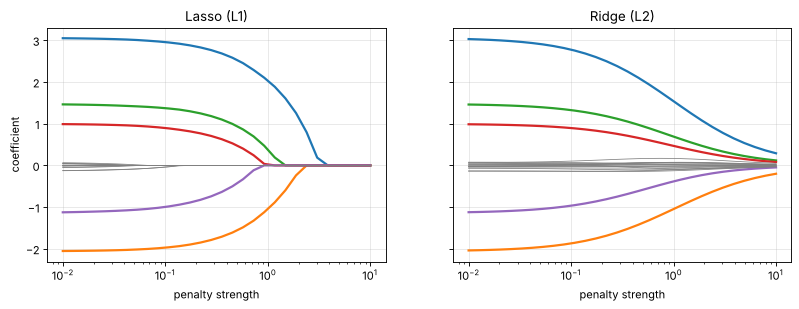

penalty=0.1 일 때 0이 아닌 계수 수  Lasso: 7  Ridge: 20


In [10]:
from sklearn.linear_model import Lasso, Ridge
n, p_feat = 200, 20
X = rng.normal(size=(n, p_feat))
true_coef = np.zeros(p_feat); true_coef[:5] = [3, -2, 1.5, 1, -1]
y = X @ true_coef + rng.normal(0, 1, n)

alphas = np.logspace(-2, 1, 30)
lasso_path = np.array([Lasso(alpha=a, max_iter=10000).fit(X, y).coef_ for a in alphas])
ridge_path = np.array([Ridge(alpha=a * n).fit(X, y).coef_ for a in alphas])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, path, name in zip(axes, [lasso_path, ridge_path], ["Lasso (L1)", "Ridge (L2)"]):
    ax.plot(alphas, path[:, :5], lw=2); ax.plot(alphas, path[:, 5:], color="gray", lw=0.7)
    ax.set_xscale("log"); ax.set_title(name); ax.set_xlabel("penalty strength")
axes[0].set_ylabel("coefficient"); plt.show()
print("penalty=0.1 일 때 0이 아닌 계수 수  Lasso:", int(np.sum(lasso_path[10] != 0)), " Ridge:", int(np.sum(ridge_path[10] != 0)))

회색 선(쓸모없는 15개 특성)이 Lasso에서는 일찍 **정확히 0**이 되고, Ridge에서는 작아지기만 할 뿐 0이 되지 않습니다. 이것이 Lasso가 "변수 선택"을 한다는 말의 의미입니다.

---
## 직접 해보기

아래 세 문제를 **먼저 스스로** 풀어 보세요. 정답 예시는 맨 아래에 있습니다.

1. **(부트스트랩)** 두 변수의 상관계수에 대한 부트스트랩 95% 신뢰구간을 구하세요. (힌트: 행 단위로 함께 복원추출해야 합니다.)
2. **(검정력)** 실제 효과가 0.2(표준편차 단위)일 때, 그룹당 n=50, 100, 400에서 p<0.05가 나올 확률(검정력)을 시뮬레이션으로 구하세요.
3. **(승자의 저주)** 2번에서 n=50일 때 "유의하게 나온 실험만" 모아 추정된 효과의 평균을 구하세요. 참값 0.2와 비교하면?

In [11]:
# TODO 1: 상관계수의 부트스트랩 신뢰구간
x1 = rng.normal(size=60); x2 = 0.5 * x1 + rng.normal(size=60)
# 여기에 작성

# TODO 2: 검정력 시뮬레이션

# TODO 3: 유의한 실험만 모았을 때의 효과 추정치 평균

---
## 정답 예시 (먼저 풀어 본 뒤 확인)

In [12]:
# 1. 상관계수 부트스트랩: (x1, x2) 쌍을 유지한 채 행을 복원추출
B = 5000
idx = rng.integers(0, len(x1), size=(B, len(x1)))
boot_r = np.array([np.corrcoef(x1[i], x2[i])[0, 1] for i in idx])
print("표본 상관계수 =", round(np.corrcoef(x1, x2)[0, 1], 3), " 95% CI =", np.percentile(boot_r, [2.5, 97.5]).round(3))

표본 상관계수 = 0.615  95% CI = [0.432 0.751]


In [13]:
# 2. 검정력  /  3. 승자의 저주
def simulate(n, effect=0.2, reps=4000):
    a = rng.normal(0, 1, size=(reps, n)); b = rng.normal(effect, 1, size=(reps, n))
    p = stats.ttest_ind(a, b, axis=1).pvalue
    est = b.mean(axis=1) - a.mean(axis=1)
    return p, est

for n in [50, 100, 400]:
    p, est = simulate(n)
    sig = p < 0.05
    print(f"n={n:3d}  검정력={sig.mean():.2f}   전체 추정 평균={est.mean():.3f}   유의한 실험만의 추정 평균={est[sig].mean():.3f}")

n= 50  검정력=0.17   전체 추정 평균=0.199   유의한 실험만의 추정 평균=0.488


n=100  검정력=0.29   전체 추정 평균=0.198   유의한 실험만의 추정 평균=0.364
n=400  검정력=0.81   전체 추정 평균=0.198   유의한 실험만의 추정 평균=0.221


**해석**: 검정력이 낮은 실험(n=50)에서는 "유의하게 나온 결과"만 모으면 효과가 참값(0.2)의 약 2배로 **과대추정**됩니다. 유의성으로 걸러낸 결과만 발표되면 문헌 전체가 과장되는 이유이며(Ioannidis, 2005; Kohavi et al., 2022 *Intuition Busters*), 논문의 작은 표본·큰 효과를 의심해야 하는 근거입니다.

---
## 논문으로 돌아가기

| 방금 한 것 | 논문에서 확인할 곳 |
|---|---|
| 3절 부트스트랩 | Efron (1979) 서론의 문제 설정: "분포를 모르는 통계량의 표준오차를 어떻게 구할까" |
| 4–5절 | ASA Statement의 6원칙 중 2번(가설이 참일 확률이 아님), 5번(효과 크기를 재지 않음) |
| 6절 | Benjamini & Hochberg (1995)의 절차 정의와 Bonferroni 대비 검정력 비교 실험 |
| 7절 | Tibshirani (1996)의 Lasso·Ridge 기하 그림(마름모 vs 원)과 계수 경로 그림 |

## 기억 점검 (답을 가리고 말로 설명해 보기)

1. 표준편차와 표준오차의 차이는? n을 100배로 늘리면 각각 어떻게 되나?
2. "95% 신뢰구간"의 95%는 무엇에 대한 확률인가?
3. 귀무가설이 참일 때 p-value는 어떤 분포를 따르나? 그 사실이 유의수준의 의미와 어떻게 연결되나?
4. FWER(Bonferroni)과 FDR(BH)이 통제하는 것은 각각 무엇인가?
5. L1 벌점은 왜 계수를 0으로 만들고 L2는 그렇지 않은가? (그림으로 설명)

<details><summary>답 확인</summary>

1. SD는 데이터 자체의 퍼짐(표본이 커져도 일정), SE는 추정치의 흔들림($\sigma/\sqrt n$). n이 100배면 SE는 1/10.
2. 구간을 만드는 **절차**를 반복했을 때 참값을 포함하는 구간의 비율. 이미 계산된 한 구간에 대한 확률이 아님.
3. 균등분포. 그래서 p<α일 확률이 정확히 α이고, α가 1종 오류율이 된다.
4. FWER: 가짜 발견이 **하나라도** 나올 확률. FDR: 발견한 것 중 가짜의 **기대 비율**.
5. L1 제약 영역(마름모)은 축 위에 꼭짓점이 있어 등고선이 꼭짓점에서 닿기 쉽고, 그 점에서는 일부 계수가 정확히 0. L2(원)는 꼭짓점이 없음.
</details>